In [24]:
import numpy as np
from scipy import fft
from scipy import signal as sig
from io import StringIO
from matplotlib import pyplot as plt
%matplotlib inline

In [52]:
def load_keysight_csv(fn):
    with open(fn, 'r') as f:
        header = {}
        while (line := f.readline().strip()) != 'DATA':
            if ',' in line:
                key, _, value = line.partition(',')
                header[key] = value
        data = f.read()
        data = np.genfromtxt(StringIO(data), delimiter=',')
        return header, data

Fundamental peak: 7996500.0 -27.0907135009766
Frequency spacing is 49.973751 kHz


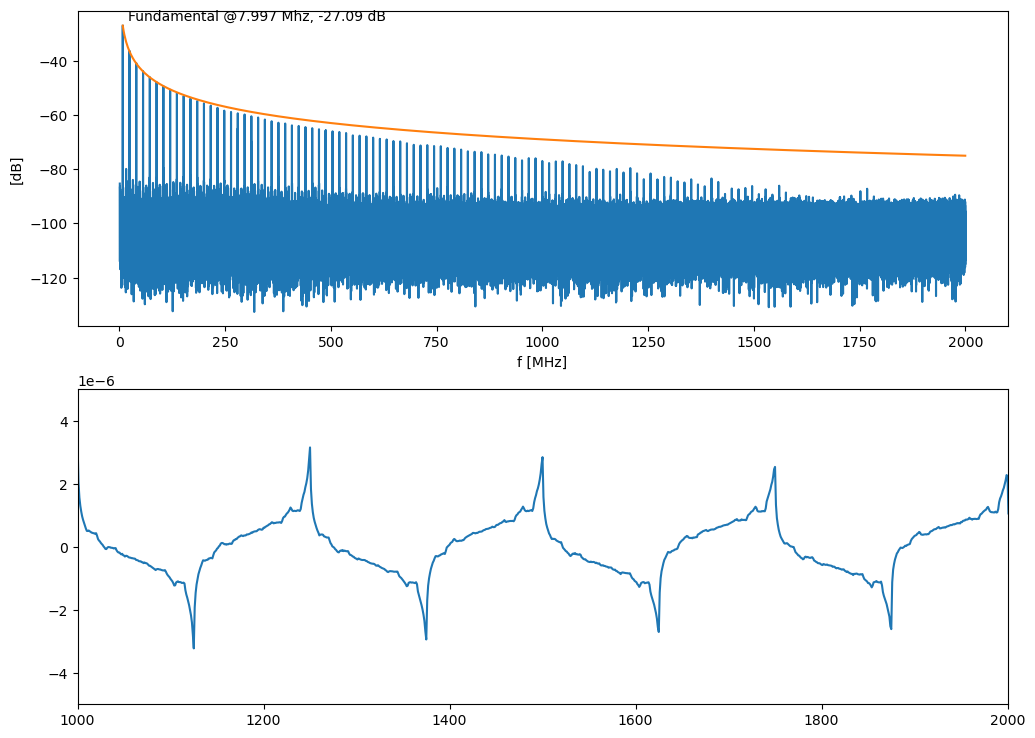

In [96]:
def plot_freq(fn):
    header_amp, data_amp = load_keysight_csv(fn)
    freq = data_amp[:,0]
    amp = data_amp[:,1]
    start_freq = float(header_amp['Start Frequency'])
    stop_freq = float(header_amp['Stop Frequency'])
    freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
    
    peaks, props = sig.find_peaks(amp, threshold=40)
    fundamental_idx = peaks[0]
    print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))
    ax1.plot(freq/1e6, amp)
    ax1.set_xlabel('f [MHz]')
    ax1.set_ylabel('[dB]')
    ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
                (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
                xytext=(5, 5),
                xycoords='data',
                textcoords='offset pixels',
               )
    
    freq_space = np.linspace(freq[fundamental_idx], stop_freq, 1000)
    ax1.plot(freq_space/1e6, 10*np.log10((np.sqrt(10**(amp[fundamental_idx]/10)) / (freq_space/freq[fundamental_idx]))**2))

    print(f'Frequency spacing is {freq_spacing/1e3:.6f} kHz')
    
    fft_data = np.hstack([
        np.zeros(round(start_freq / freq_spacing) + 1),
        10**(amp/20)])
    fft_data = np.hstack([fft_data[1::-1], fft_data])
    
    time_domain_amp = fft.ifft(fft_data)
    
    ax2.plot(time_domain_amp)
    ax2.set_xlim([1000, 2000])
    ax2.set_ylim([-0.5e-5, 0.5e-5])

plot_freq('amp_out_span_2g_rbw_10k_40kpt_0000.csv')

Fundamental peak: 7996500.0 -38.6481513977051
Frequency spacing is 49.973751 kHz


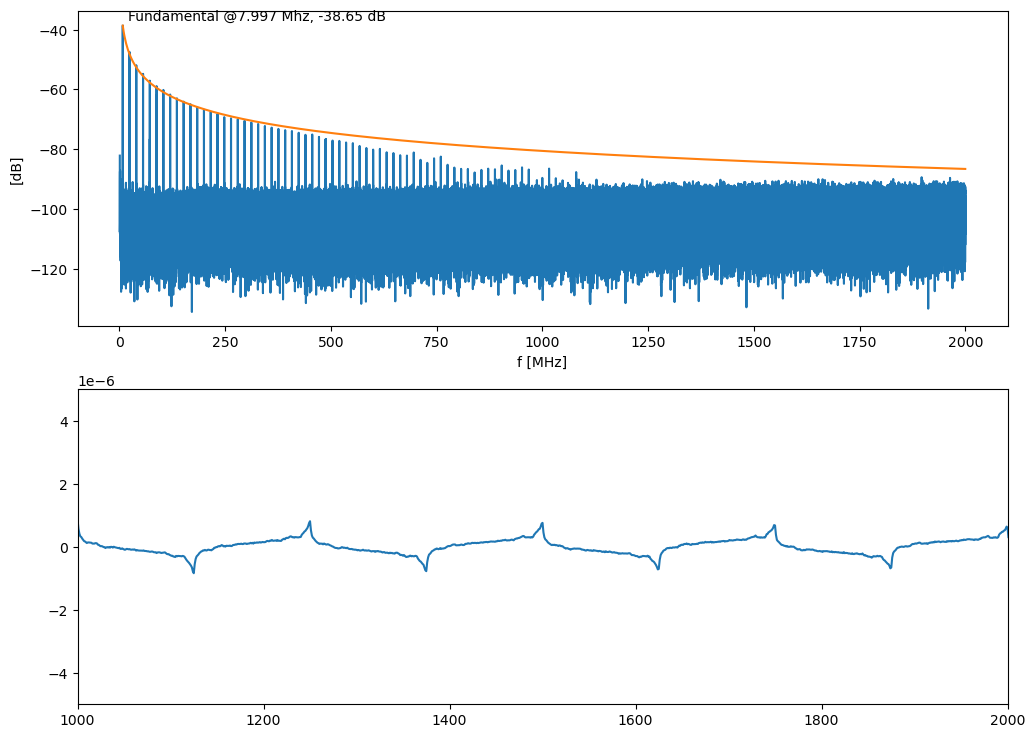

In [97]:
plot_freq('board_out_span_2g_rbw_10k_40kpt.csv')